In [13]:
!pip install -q datasets transformers evaluate rouge-score accelerate

Using device: cuda
GPU: Tesla T4
Split sizes -> Train: 20000 Val: 1000 Test: 1000
Article Length (words) -> Mean: 369.93 | Median: 295.0 | 95th pct: 920.0
Summary Length (words) -> Mean: 21.1 | Median: 21.0 | 95th pct: 29.0
Compression Ratio (Article / Summary): 17.53
Novel Bigrams in Summary (%): 86.4


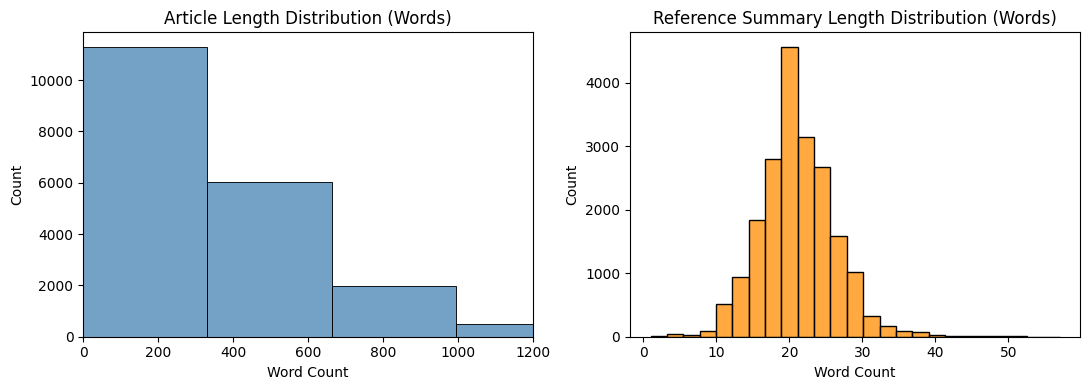

In [14]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load XSum dataset (fallback to GEM/xsum if needed)
try:
    raw_ds = load_dataset("EdinburghNLP/xsum")
except Exception:
    raw_ds = load_dataset("GEM/xsum")

# Sample exact 20,000 train, 1,000 validation, 1,000 test with fixed seed
train_ds = raw_ds["train"].shuffle(seed=SEED).select(range(20000))
val_ds = raw_ds["validation"].shuffle(seed=SEED).select(range(1000))
test_ds = raw_ds["test"].shuffle(seed=SEED).select(range(1000))

print("Split sizes -> Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))

# Compute Dataset Statistics on Train Subset
art_lens = [len(x.split()) for x in train_ds["document"]]
sum_lens = [len(x.split()) for x in train_ds["summary"]]

def get_stats(arr):
    return round(np.mean(arr), 2), round(np.median(arr), 2), round(np.percentile(arr, 95), 2)

art_mean, art_med, art_p95 = get_stats(art_lens)
sum_mean, sum_med, sum_p95 = get_stats(sum_lens)
comp_ratio = round(art_mean / sum_mean, 2)

# Novel bigrams percentage
def novel_bigram_pct(docs, sums):
    novel_total, total_bi = 0, 0
    for d, s in zip(docs, sums):
        d_words = d.lower().split()
        s_words = s.lower().split()
        d_bi = set(zip(d_words, d_words[1:]))
        s_bi = list(zip(s_words, s_words[1:]))
        if len(s_bi) > 0:
            novel_total += sum(1 for b in s_bi if b not in d_bi)
            total_bi += len(s_bi)
    return round((novel_total / total_bi) * 100, 2)

novel_pct = novel_bigram_pct(train_ds["document"][:3000], train_ds["summary"][:3000])

print("Article Length (words) -> Mean:", art_mean, "| Median:", art_med, "| 95th pct:", art_p95)
print("Summary Length (words) -> Mean:", sum_mean, "| Median:", sum_med, "| 95th pct:", sum_p95)
print("Compression Ratio (Article / Summary):", comp_ratio)
print("Novel Bigrams in Summary (%):", novel_pct)

# EDA Plot (Figure 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(art_lens, bins=40, ax=axes[0], color="steelblue")
axes[0].set_xlim(0, 1200)
axes[0].set_title("Article Length Distribution (Words)")
axes[0].set_xlabel("Word Count")

sns.histplot(sum_lens, bins=25, ax=axes[1], color="darkorange")
axes[1].set_title("Reference Summary Length Distribution (Words)")
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.savefig("eda_xsum.png", dpi=300)
plt.show()

In [15]:
rouge = evaluate.load("rouge")

test_docs = test_ds["document"]
test_refs = test_ds["summary"]

# Lead-1 Baseline: first sentence (first line) of the article
lead1_preds = [doc.split("\\n")[0].strip() if len(doc.strip()) > 0 else "" for doc in test_docs]

lead1_scores = rouge.compute(predictions=lead1_preds, references=test_refs, use_stemmer=True)
lead1_len = round(np.mean([len(p.split()) for p in lead1_preds]), 2)

print("--- Lead-1 Baseline Test Results ---")
print("ROUGE-1:", round(lead1_scores["rouge1"] * 100, 2))
print("ROUGE-2:", round(lead1_scores["rouge2"] * 100, 2))
print("ROUGE-L:", round(lead1_scores["rougeL"] * 100, 2))
print("Avg Generated Length (words):", lead1_len)

--- Lead-1 Baseline Test Results ---
ROUGE-1: 9.9
ROUGE-2: 2.22
ROUGE-L: 6.58
Avg Generated Length (words): 362.04


In [16]:
from collections import Counter

# Simple word tokenizer & vocabulary fitted strictly on training split
MAX_VOCAB = 15000
MAX_ART_LEN = 400
MAX_SUM_LEN = 40

def tokenize(text):
    return text.lower().strip().split()

counter = Counter()
for doc, summ in zip(train_ds["document"], train_ds["summary"]):
    counter.update(tokenize(doc)[:MAX_ART_LEN])
    counter.update(tokenize(summ)[:MAX_SUM_LEN])

vocab = ["<pad>", "<sos>", "<eos>", "<unk>"] + [w for w, _ in counter.most_common(MAX_VOCAB - 4)]
word2idx = dict(zip(vocab, range(len(vocab))))
idx2word = dict(zip(range(len(vocab)), vocab))
VOCAB_SIZE = len(vocab)
print("Custom Seq2Seq Vocabulary Size:", VOCAB_SIZE)

def encode_text(text, max_len, add_eos=False):
    tokens = tokenize(text)[:max_len - (1 if add_eos else 0)]
    ids = [word2idx.get(t, 3) for t in tokens]
    if add_eos:
        ids.append(2)
    return ids

class Seq2SeqDataset(Dataset):
    def __init__(self, docs, sums):
        self.src = [encode_text(d, MAX_ART_LEN, add_eos=False) for d in docs]
        self.trg = [[1] + encode_text(s, MAX_SUM_LEN - 1, add_eos=True) for s in sums]
    def __len__(self):
        return len(self.src)
    def __getitem__(self, idx):
        return torch.tensor(self.src[idx], dtype=torch.long), torch.tensor(self.trg[idx], dtype=torch.long)

def collate_fn(batch):
    srcs, trgs = zip(*batch)
    src_pad = nn.utils.rnn.pad_sequence(srcs, batch_first=True, padding_value=0)
    trg_pad = nn.utils.rnn.pad_sequence(trgs, batch_first=True, padding_value=0)
    return src_pad, trg_pad

train_loader = DataLoader(Seq2SeqDataset(train_ds["document"], train_ds["summary"]), batch_size=64, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(Seq2SeqDataset(val_ds["document"], val_ds["summary"]), batch_size=64, shuffle=False, collate_fn=collate_fn)

# GRU Encoder-Decoder with Dot-Product Attention
class AttnSeq2Seq(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hid_dim=256):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.enc = nn.GRU(emb_dim, hid_dim, batch_first=True)
        self.dec = nn.GRU(emb_dim + hid_dim, hid_dim, batch_first=True)
        self.fc = nn.Linear(hid_dim * 2, vocab_size)

    def forward(self, src, trg):
        enc_out, hid = self.enc(self.emb(src))
        outputs = []
        inp = trg[:, 0].unsqueeze(1)
        for t in range(1, trg.size(1)):
            emb_t = self.emb(inp)
            # Attention weights over encoder outputs
            scores = torch.bmm(hid.transpose(0, 1), enc_out.transpose(1, 2))
            attn = torch.softmax(scores, dim=-1)
            ctx = torch.bmm(attn, enc_out)
            dec_in = torch.cat([emb_t, ctx], dim=-1)
            dec_out, hid = self.dec(dec_in, hid)
            pred = self.fc(torch.cat([dec_out, ctx], dim=-1))
            outputs.append(pred)
            inp = trg[:, t].unsqueeze(1)
        return torch.cat(outputs, dim=1)

    @torch.no_grad()
    def generate(self, src, max_len=35):
        enc_out, hid = self.enc(self.emb(src))
        inp = torch.full((src.size(0), 1), 1, dtype=torch.long, device=src.device)
        preds = []
        for _ in range(max_len):
            emb_t = self.emb(inp)
            scores = torch.bmm(hid.transpose(0, 1), enc_out.transpose(1, 2))
            attn = torch.softmax(scores, dim=-1)
            ctx = torch.bmm(attn, enc_out)
            dec_out, hid = self.dec(torch.cat([emb_t, ctx], dim=-1), hid)
            logits = self.fc(torch.cat([dec_out, ctx], dim=-1))
            inp = logits.argmax(dim=-1)
            preds.append(inp)
        return torch.cat(preds, dim=1)

model1 = AttnSeq2Seq(VOCAB_SIZE).to(device)
optimizer = torch.optim.Adam(model1.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=0)

start_m1 = time.time()
train_losses, val_losses = [], []
best_val_loss = float("inf")
patience_cnt = 0

for epoch in range(1, 8):
    model1.train()
    t_loss = 0
    for src, trg in train_loader:
        src, trg = src.to(device), trg.to(device)
        optimizer.zero_grad()
        out = model1(src, trg)
        loss = criterion(out.reshape(-1, VOCAB_SIZE), trg[:, 1:].reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model1.parameters(), 1.0)
        optimizer.step()
        t_loss += loss.item()
    t_loss /= len(train_loader)

    model1.eval()
    v_loss = 0
    with torch.no_grad():
        for src, trg in val_loader:
            src, trg = src.to(device), trg.to(device)
            out = model1(src, trg)
            loss = criterion(out.reshape(-1, VOCAB_SIZE), trg[:, 1:].reshape(-1))
            v_loss += loss.item()
    v_loss /= len(val_loader)
    train_losses.append(t_loss)
    val_losses.append(v_loss)
    print("Epoch", epoch, "| Train Loss:", round(t_loss, 4), "| Val Loss:", round(v_loss, 4))

    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model1.state_dict(), "best_gru_seq2seq.pt")
        patience_cnt = 0
    else:
        patience_cnt += 1
        if patience_cnt >= 2:
            print("Early stopping triggered.")
            break

m1_time = round(time.time() - start_m1, 1)
print("Model 1 Training Time (sec):", m1_time)

# Evaluate Model 1 on Test Set
model1.load_state_dict(torch.load("best_gru_seq2seq.pt"))
model1.eval()
test_loader = DataLoader(Seq2SeqDataset(test_docs, test_refs), batch_size=64, shuffle=False, collate_fn=collate_fn)

m1_preds = []
for src, _ in test_loader:
    gen_ids = model1.generate(src.to(device), max_len=35).cpu().tolist()
    for seq in gen_ids:
        words = []
        for idx in seq:
            if idx == 2:
                break
            if idx > 2:
                words.append(idx2word[idx])
        m1_preds.append(" ".join(words))

m1_scores = rouge.compute(predictions=m1_preds, references=test_refs, use_stemmer=True)
m1_len = round(np.mean([len(p.split()) for p in m1_preds]), 2)
print("\\n--- Model 1 (GRU + Attention) Test Results ---")
print("ROUGE-1:", round(m1_scores["rouge1"] * 100, 2))
print("ROUGE-2:", round(m1_scores["rouge2"] * 100, 2))
print("ROUGE-L:", round(m1_scores["rougeL"] * 100, 2))
print("Avg Generated Length (words):", m1_len)

Custom Seq2Seq Vocabulary Size: 15000
Epoch 1 | Train Loss: 6.1037 | Val Loss: 5.4728
Epoch 2 | Train Loss: 5.1179 | Val Loss: 5.0105
Epoch 3 | Train Loss: 4.6052 | Val Loss: 4.8145
Epoch 4 | Train Loss: 4.2265 | Val Loss: 4.7222
Epoch 5 | Train Loss: 3.8983 | Val Loss: 4.687
Epoch 6 | Train Loss: 3.5981 | Val Loss: 4.6831
Epoch 7 | Train Loss: 3.3239 | Val Loss: 4.7228
Model 1 Training Time (sec): 350.5
\n--- Model 1 (GRU + Attention) Test Results ---
ROUGE-1: 16.92
ROUGE-2: 2.91
ROUGE-L: 14.05
Avg Generated Length (words): 17.17


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "t5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)

class T5XSumDataset(Dataset):
    def __init__(self, docs, sums):
        inputs = ["summarize: " + str(d) for d in list(docs)]
        targets = [str(s) for s in list(sums)]
        self.enc = tokenizer(inputs, max_length=400, truncation=True, padding="max_length", return_tensors="pt")
        self.dec = tokenizer(text_target=targets, max_length=48, truncation=True, padding="max_length", return_tensors="pt")
        labels = self.dec["input_ids"].clone()
        labels[labels == tokenizer.pad_token_id] = -100
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.enc["input_ids"][idx],
            self.enc["attention_mask"][idx],
            self.labels[idx]
        )

print("Tokenizing T5 datasets...")
t5_train_loader = DataLoader(T5XSumDataset(train_ds["document"], train_ds["summary"]), batch_size=64, shuffle=True)
t5_val_loader = DataLoader(T5XSumDataset(val_ds["document"], val_ds["summary"]), batch_size=64, shuffle=False)

t5_opt = torch.optim.AdamW(t5_model.parameters(), lr=3e-4)
scaler = torch.amp.GradScaler("cuda")
start_m2 = time.time()
t5_train_losses, t5_val_losses = [], []

print("Training T5-small...")
for epoch in range(1, 3):
    t5_model.train()
    tr_loss = 0
    for inp_ids, mask, lbls in t5_train_loader:
        inp_ids, mask, lbls = inp_ids.to(device), mask.to(device), lbls.to(device)
        t5_opt.zero_grad()
        with torch.amp.autocast("cuda"):
            out = t5_model(input_ids=inp_ids, attention_mask=mask, labels=lbls)
            loss = out.loss
        scaler.scale(loss).backward()
        scaler.step(t5_opt)
        scaler.update()
        tr_loss += loss.item()
    tr_loss /= len(t5_train_loader)

    t5_model.eval()
    vl_loss = 0
    with torch.no_grad():
        for inp_ids, mask, lbls in t5_val_loader:
            inp_ids, mask, lbls = inp_ids.to(device), mask.to(device), lbls.to(device)
            with torch.amp.autocast("cuda"):
                out = t5_model(input_ids=inp_ids, attention_mask=mask, labels=lbls)
            vl_loss += out.loss.item()
    vl_loss /= len(t5_val_loader)
    t5_train_losses.append(tr_loss)
    t5_val_losses.append(vl_loss)
    print("T5 Epoch", epoch, "| Train Loss:", round(tr_loss, 4), "| Val Loss:", round(vl_loss, 4))

m2_time = round(time.time() - start_m2, 1)
print("Model 2 (t5-small) Training Time (sec):", m2_time)

print("Generating test summaries...")
t5_model.eval()
m2_preds = []
test_docs_list = list(test_docs)
for i in range(0, len(test_docs_list), 64):
    batch_texts = ["summarize: " + str(d) for d in test_docs_list[i:i+64]]
    enc = tokenizer(batch_texts, max_length=400, truncation=True, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        gen = t5_model.generate(
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            max_new_tokens=36,
            num_beams=2,
            no_repeat_ngram_size=3,
            early_stopping=True
        )
    m2_preds.extend(tokenizer.batch_decode(gen, skip_special_tokens=True))

m2_scores = rouge.compute(predictions=m2_preds, references=list(test_refs), use_stemmer=True)
m2_len = round(np.mean([len(p.split()) for p in m2_preds]), 2)
print("\\n--- Model 2 (Fine-tuned T5-small) Test Results ---")
print("ROUGE-1:", round(m2_scores["rouge1"] * 100, 2))
print("ROUGE-2:", round(m2_scores["rouge2"] * 100, 2))
print("ROUGE-L:", round(m2_scores["rougeL"] * 100, 2))
print("Avg Generated Length (words):", m2_len)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Tokenizing T5 datasets...
Training T5-small...
T5 Epoch 1 | Train Loss: 2.8667 | Val Loss: 2.5591


In [ ]:
# Plot Training & Validation Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(train_losses)+1), train_losses, marker='o', label='Train Loss')
axes[0].plot(range(1, len(val_losses)+1), val_losses, marker='s', label='Val Loss')
axes[0].set_title('Model 1 (GRU + Attention) Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

axes[1].plot(range(1, len(t5_train_losses)+1), t5_train_losses, marker='o', label='Train Loss')
axes[1].plot(range(1, len(t5_val_losses)+1), t5_val_losses, marker='s', label='Val Loss')
axes[1].set_title('Model 2 (Fine-Tuned T5-small) Loss Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cross-Entropy Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig("loss_xsum.png", dpi=300)
plt.show()

# Print 5 Qualitative Examples (Article Excerpt, Reference, Model 1, Model 2)
print("\\n=== FIVE QUALITATIVE TEST EXAMPLES ===")
for idx in range(5):
    print("\\n--- Example", idx + 1, "---")
    print("Article Excerpt:", test_docs[idx][:220].replace("\\n", " "), "...")
    print("Reference:", test_refs[idx])
    print("Model 1 (GRU):", m1_preds[idx])
    print("Model 2 (T5-small):", m2_preds[idx])

# Print 20 T5 summaries for hallucination inspection
print("\\n=== FIRST 20 T5 SUMMARIES FOR HALLUCINATION CHECK ===")
for idx in range(20):
    print(idx + 1, "| Ref:", test_refs[idx])
    print("   | T5 :", m2_preds[idx])